<a href="https://colab.research.google.com/github/wavejumper3/Machine-Learning-349/blob/main/HW5/diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1:
Load the dataset into a Pandas DataFrame from the source repository or course mirror, assigning appropriate column names.

# Extensive Explanation:
First, the program installs the `sklearn` library. By putting an ! in front of a line, the notebook executes it as a terminal command, rather than as python code, allowing for things such as installing libraries.

We then import pandas. Pandas is the library we use for Pandas DataFrames (see later). Importing pandas as pd is purely convention, and makes code easier for others to parse.

After this, we import the only function we need from `sklearn`, which is `fetch_openml()`. This function takes a repository ID and returns its full contents. We don't need to use anything else, so importing just that function is clearer. It is contained within `sklearn.datasets`, a subset of `sklearn`, hence the specification.

We then fetch the dataset. The number `43582` is the ID of the dataset, hence why `fetch_openml()` takes it as an id. this is stored into the variable `diabeties`.

The returned dataset is not in the proper format for a pandas dataframe, so we first have to seperate it into rows and columns. This is done on the next two lines, seperating the data into features and targets as two seperate variables. This will allow us to create a dataframe using the `pd.concat()` function.

The function is then called, combining `X` and `y` into a proper Pandas Dataframe. Naming the dataframe `df` is again a matter of convention.

In [6]:
!pip install sklearn

import pandas as pd
from sklearn.datasets import fetch_openml

diabeties = fetch_openml(data_id=43582, as_frame=True)

X = diabeties.data
y = diabeties.target

df = pd.concat([X, y], axis=1)

  Using cached sklearn-0.0.post12.tar.gz (2.6 kB)
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
ERROR: Failed to build 'sklearn' when getting requirements to build wheel



# Task 2:
Use structural inspection methods (head(), info(), describe()) to analyze feature distributions and identify non-standard placeholder values.

# Extensive Explanation

This part calls each of the three given inspection methods as asked, inside of a `display()` function, which shows them in the output.

Looking at the output, the minimum value of zero for `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` and `BMI` are all suspect, and probably non-standard placeholder values. I'm not a doctor, but I don't think any of those numbers would be zero in the average person.

We can also assume that the Outcome variable is binary, 0/1, for having or not having diabeties.

In [9]:
display(df.head())

display(df.describe())

display(df.head())

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6.0,148.0,72.0,35.0,0.0,33.6,0.627,50.0,1.0
1,1.0,85.0,66.0,29.0,0.0,26.6,0.351,31.0,0.0
2,8.0,183.0,64.0,0.0,0.0,23.3,0.672,32.0,1.0
3,1.0,89.0,66.0,23.0,94.0,28.1,0.167,21.0,0.0
4,0.0,137.0,40.0,35.0,168.0,43.1,2.288,33.0,1.0


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6.0,148.0,72.0,35.0,0.0,33.6,0.627,50.0,1.0
1,1.0,85.0,66.0,29.0,0.0,26.6,0.351,31.0,0.0
2,8.0,183.0,64.0,0.0,0.0,23.3,0.672,32.0,1.0
3,1.0,89.0,66.0,23.0,94.0,28.1,0.167,21.0,0.0
4,0.0,137.0,40.0,35.0,168.0,43.1,2.288,33.0,1.0



# Task 3:
Quantify and handle implicit missing values using SimpleImputer.

# Extensive Explanation:

I first import `SimpleImputer` from `sklearn.impute`, which is the class that is mentioned in the task definition, followed by `numpy`, for its `np.nan` value. `np.nan` is used for explicitly missing values in dataframes before imputation.

After this, I define the columns that have placeholder values, and count the amount of zeros in each. This should be equivalent to the amount of NaNs after replacing the implicit missing values with explicit ones.

A copy of `df` is created, called `df_imputable`, which will be the dataframe with explicit missing values. Isolating the placeholder columns from the new dataframe, every zero is replaced with np.nan.

The number of null (`np.nan`) values is then printed, to verify the first step went properly.

A SimpleImputer is now created, with the mean strategy, which will replace all null values with the mean value of that data column. This is then once again applied only to the columns with missing values. It could be applied to the entire dataframe, as missing values are now explicit, but it still works this way.

The code then prints out the remaining Null value count, which should be zero across all columns. If this is true, we can continue to the next cell. The final print statement is purely decorative.

In [12]:
from sklearn.impute import SimpleImputer
import numpy as np

placeholder_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

print("0s before replacement:")
for col in placeholder_cols:
    zeros_count = (df[col] == 0).sum() # wonderful way to write it, very proud
    print(f"{col}: {zeros_count}")

df_imputable = df.copy()
df_imputable[placeholder_cols] = df_imputable[placeholder_cols].replace(0, np.nan)

print("\nNaNs after replacement:")
print(df_imputable[placeholder_cols].isnull().sum())

imputer = SimpleImputer(strategy='mean')
df_imputable[placeholder_cols] = imputer.fit_transform(df_imputable[placeholder_cols])
df_imputed = df_imputable.copy()

print("\nNaNs after SimpleImputer:")
print(df_imputed[placeholder_cols].isnull().sum())

print("\nImputated!")

0s before replacement:
Glucose: 5
BloodPressure: 35
SkinThickness: 227
Insulin: 374
BMI: 11

NaNs after replacement:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

NaNs after SimpleImputer:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64

Imputated!



# Task 4:
Build a Scikit-Learn ColumnTransformer and Pipeline that applies appropriate scaling.

# Extensive Explanation

First, several classes must be imported, the first two defined explicitly by the task, and the last needed for the scaling specifically.

As this dataset has no categorical features, we only createa a numeric pipeline, including a StandardScaler.

This pipeline is then put into a ColumnTransformer, which is then once again put inside of a full_pipeline, creating a russian nesting doll of abstractions that simply applies a StandardScaler to everything. This is a matter of convention, and the task given.

We finally apply this pipeline to the dataframe, and print out a short message confirming nothing went wrong during this process.

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

numeric_features = df_imputed.select_dtypes(
    include=np.number
).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler())
])


preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features)
    ]
)

full_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor)
])

df_processed = full_pipeline.fit_transform(df_imputed)

print("complete!")


complete!



# Task 5:
Train both a Hard Voting Classifier and a Soft Voting Classifier combining base models (e.g., Logistic Regression, Support Vector Classifier, and a Decision Tree), then evaluate their test accuracy and classification reports. Use must use appropriate plots to show the results.

# Extensive Explanation

This is a long one, fair warning.



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

=== Hard Voting Classifier Classification Report ===
              precision    recall  f1-score   support

         0.0       0.76      0.78      0.77       100
         1.0       0.58      0.56      0.57        54

    accuracy                           0.70       154
   macro avg       0.67      0.67      0.67       154
weighted avg       0.70      0.70      0.70       154

Accuracy: 0.7013

=== Soft Voting Classifier Classification Report ===
              precision    recall  f1-score   support

         0.0       0.79      0.78      0.78       100
         1.0       0.60      0.61      0.61        54

    accuracy                           0.72       154
   macro avg       0.69      0.70      0.69       154
weighted avg       0.72      0.72      0.72       154

Accuracy: 0.7208



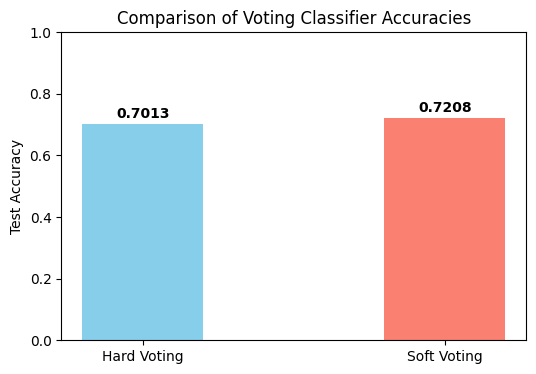

In [19]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report


X_data = df_imputed.drop(columns=['Outcome'])
y_data = df_imputed['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.2, random_state=4, stratify=y_data
)


log_clf = LogisticRegression(random_state=4)
svc_clf = SVC(probability=True, random_state=4)
dt_clf = DecisionTreeClassifier(random_state=4)


hard_voting = VotingClassifier(
    estimators=[('lr', log_clf), ('svc', svc_clf), ('dt', dt_clf)],
    voting='hard'
)

soft_voting = VotingClassifier(
    estimators=[('lr', log_clf), ('svc', svc_clf), ('dt', dt_clf)],
    voting='soft'
)

#train
hard_voting.fit(X_train, y_train)
soft_voting.fit(X_train, y_train)

#eval
y_pred_hard = hard_voting.predict(X_test)
y_pred_soft = soft_voting.predict(X_test)

acc_hard = accuracy_score(y_test, y_pred_hard)
acc_soft = accuracy_score(y_test, y_pred_soft)

print("=== Hard Voting Classifier Classification Report ===")
print(classification_report(y_test, y_pred_hard))
print(f"Accuracy: {acc_hard:.4f}\n")

print("=== Soft Voting Classifier Classification Report ===")
print(classification_report(y_test, y_pred_soft))
print(f"Accuracy: {acc_soft:.4f}\n")

#plot
plt.figure(figsize=(6, 4))
models = ['Hard Voting', 'Soft Voting']
accuracies = [acc_hard, acc_soft]

plt.bar(models, accuracies, color=['skyblue', 'salmon'], width=0.4)
plt.ylim(0, 1.0)
plt.ylabel('Test Accuracy')
plt.title('Comparison of Voting Classifier Accuracies')
for i, acc in enumerate(accuracies):
    plt.text(i, acc + 0.02, f"{acc:.4f}", ha='center', fontweight='bold')

plt.show()


# Task 6:
Train a Bagging Classifier using decision tree base estimators with bootstrap sampling enabled and out-of-bag evaluation, and compare the OOB score against held-out test accuracy. Plot the accuracy results in one graph.


# Extensive explanation
First, I import the `BaggingClassifier` class from `sklearn`.

I create a bagging classifier, `bagging_clf`, using a descision tree estimator with 100 trees.

I train it.
I get the OOB evaluation score,

I use it to predict the test set and check its accuracy, to compare it to the OOB score.

I then configure a plot with matplotlib, label it, and so forth. I don't know what part of the plotting you'd specifically want an explanation of, because "extensive explanation" has no upper bound on depth. I'm going to cover all my bases here:

I create a plot with a size of 3 by 2. This is a nice, readable size.
I then create an array named "metrix" that contains both values to be displayed in the graph. I create it seperately for readability, as putting it inline would be less easy to read.
I then create an array called "scores" with the actual data. Note that the order here matches the order in "Metrics". This ensures that the labels will match the actual data shown. If these were not in the same order, the plot's labels would be wrong.

After this, I use `plt.bar()` to create a bar graph, utilizing the previously defined metrics and score variables, containing the labels and data values, respectively. These are then given seperate colors, also aiding in final readability. Purple and green were chosen as a plesant color combination that is easy on the eyes and different enogh to differentiate the two columns, without being so generic as other combinations, such as green and red. The colors are also in the respetive order that the plot and data values are. The order here does not matter as much, as the colors are not data-specific in any semantic sense. The bars are given a width of 0.4, making the entire graph smaller.

The graph is then mapped onto the range (0,1) on the y axis. This ensures the values are more readable, and the y axis gives sane values for what we're displaying (accuracy scores, and a predictive accuracy score).

The plot is then labeled "Accuracy" on the y axis, Both measures are measures of accuracy, making this a good descriptive label, further adding to the final graph's overall correct formatting and readability.

Next, the plot is titled. The title chosen clearly states exactly what this graph is of, without being too verbose.
The for loop then labels each bar with its actual numerical value, truncated to 4 decimal points, centered, in a bold font, right above the bar. This again makes it even more readable by giving exact values to the visuals provided.

Finally, the plot is displayed using plt.show.

out of bag score: 0.7834
held out test accuracy: 0.6948


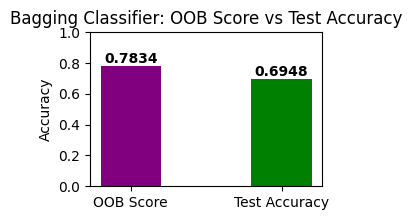

In [22]:
from sklearn.ensemble import BaggingClassifier

bagging_clf = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=4),
    n_estimators=100,
    bootstrap=True,
    oob_score=True,
    random_state=4,
    n_jobs=-1
)

bagging_clf.fit(X_train, y_train)
oob_score = bagging_clf.oob_score_

y_pred_bagging = bagging_clf.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred_bagging)


print(f"out of bag score: {oob_score:.4f}")
print(f"held out test accuracy: {test_accuracy:.4f}")

# 5. Plot the comparison in a single graph
plt.figure(figsize=(3,2))
metrics = ['OOB Score', 'Test Accuracy']
scores = [oob_score, test_accuracy]

plt.bar(metrics, scores, color=['purple', 'green'], width=0.4)
plt.ylim(0, 1.0)
plt.ylabel('Accuracy')
plt.title('Bagging Classifier: OOB Score vs Test Accuracy')
for i, score in enumerate(scores):
    plt.text(i, score + 0.02, f"{score:.4f}", ha='center', fontweight='bold')

plt.show()


# Task 7:
Train a Random Forest Classifier configured with feature subsetting, evaluate its test performance, and generate a horizontal bar plot visualizing feature importances (Mean Decrease in Impurity).


# Extensive explanation

I imported the `RandomFOrestClassifier`, as implied by the task. I then created one with the feature subsetting `max_features='sqrt'`. This subsetting controls how many features are randomly selected for consideration at each split. This introduces diversity by reducing correlation and overfitting. It's similar to the method of preventing overfitting by deactivating certian neurons in a neural network so the entire network shares the task of learning.

The model is then trained and evaluated, as before. The performance is printed out.

We then extract feature names, importances, and sort the importances. This is plotted on a larger bar chart, with various bars with named features. The plot is labeled on the X axis, and then given a title. The bars are then annotated as before.

The plot is then displayed.

On a more general level, the plot was made horizontal so that the longer bar names wouldn't overlap or cause wide spacing. Green and purple were both much too garish to look at, so a softer teal color was chosen for the bars.

Random Forest classefier preformance:
accuracy: 0.7013

              precision    recall  f1-score   support

         0.0       0.78      0.75      0.77       100
         1.0       0.57      0.61      0.59        54

    accuracy                           0.70       154
   macro avg       0.68      0.68      0.68       154
weighted avg       0.71      0.70      0.70       154



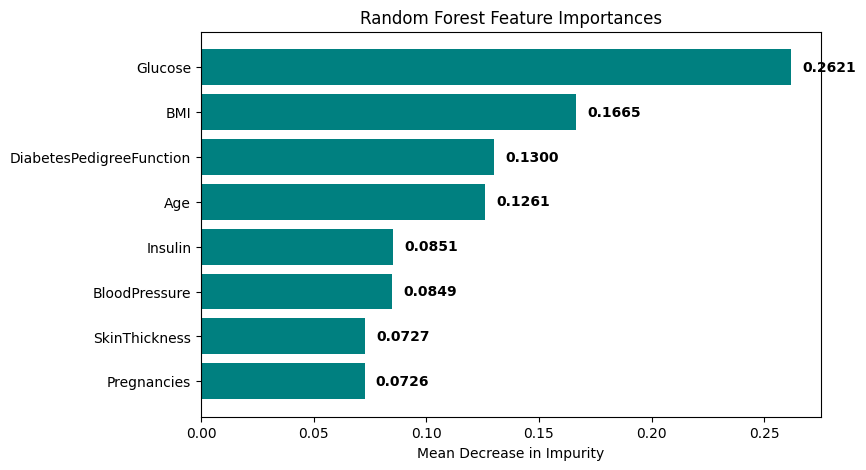

In [31]:
from sklearn.ensemble import RandomForestClassifier

rf_clf = RandomForestClassifier(
    n_estimators=100,
    max_features='sqrt',
    random_state=4,
    n_jobs=-1
)
rf_clf.fit(X_train, y_train)

y_pred_rf = rf_clf.predict(X_test)
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print("Random Forest classefier preformance:")
print(f"accuracy: {accuracy_rf:.4f}\n")
print(classification_report(y_test, y_pred_rf))

feature_names = X_data.columns.tolist()
importances = rf_clf.feature_importances_
indices = np.argsort(importances)
plt.figure(figsize=(8, 5))
plt.barh(range(len(indices)), importances[indices], color='teal', align='center')
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel('Mean Decrease in Impurity')
plt.title('Random Forest Feature Importances')

for idx, i in enumerate(indices):
    plt.text(importances[i] + 0.005, idx, f"{importances[i]:.4f}", va='center', fontweight='bold')
plt.show()


# Task 8:
Train an AdaBoost Classifier utilizing decision stumps and sequential sample weighting, and evaluate its training versus test performance to observe potential boosting generalization trends. Plot the results.

# extensive explanation

I created an estimator for the adaboost classifier to use, and then created the adaboost classifier. This model was then trained.
I had to track the sequential performance in different boosting stages, so I created two arrays, and then iterated over the two. I subtracted them from 1.0 because they're inverted, and looking at it that way makes more sense.
Staged_predict returns the different values asked for in the task definition, which made it a natural choice for this task.

I then also stored the final accuracies, printed everything out, and made yet another plot.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(


final training accuracy: 0.8225
final test accuracy:     0.6948



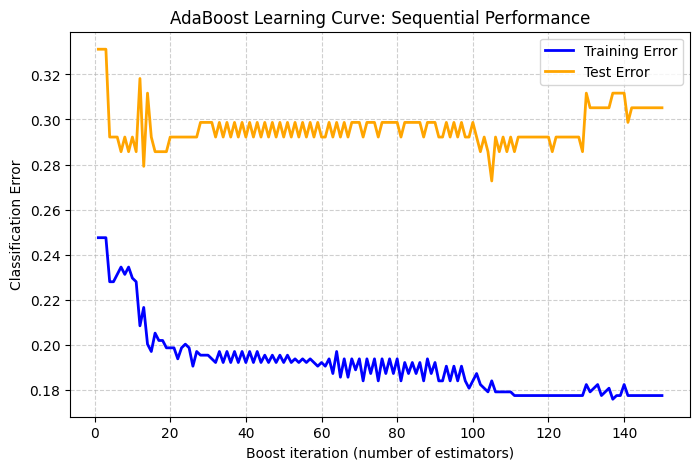

In [33]:
from sklearn.ensemble import AdaBoostClassifier


base_estimator = DecisionTreeClassifier(max_depth=1,)
ada_clf = AdaBoostClassifier(
    estimator=base_estimator,
    n_estimators=150,
    learning_rate=1.0,
    random_state=4
)

ada_clf.fit(X_train, y_train)


train_errors = []
test_errors = []

for y_pred_train in ada_clf.staged_predict(X_train):
    train_errors.append(1.0 - accuracy_score(y_train, y_pred_train))

for y_pred_test in ada_clf.staged_predict(X_test):
    test_errors.append(1.0 - accuracy_score(y_test, y_pred_test))

final_train_acc = accuracy_score(y_train, ada_clf.predict(X_train))
final_test_acc = accuracy_score(y_test, ada_clf.predict(X_test))

print(f"final training accuracy: {final_train_acc:.4f}")
print(f"final test accuracy:     {final_test_acc:.4f}\n")

plt.figure(figsize=(8, 5))
plt.plot(np.arange(1, len(train_errors) + 1), train_errors, label='Training Error', color='blue', linewidth=2)
plt.plot(np.arange(1, len(test_errors) + 1), test_errors, label='Test Error', color='orange', linewidth=2)
plt.xlabel('Boost iteration (number of estimators)')
plt.ylabel('Classification Error')
plt.title('AdaBoost Learning Curve: Sequential Performance')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## (I'm hoping that by moving my descriptions from what I hope is hopelessly verbose to about what I was doing before, I can find the cutoff point where it was no longer enough and better understand the expectation for future assignments)